# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
%matplotlib inline

import os
import re
import sys
import time
import random
import unicodedata
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import nltk
for package in ("gutenberg", "stopwords"):
    try:
        nltk.data.find(f"corpora/{package}")
    except LookupError:
        nltk.download(package, quiet=True)

from nltk.corpus import gutenberg

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

STOPWORDS = set("""a about above after again against ain all am an and any are aren aren't as at be because been before being below between both but by can couldn couldn't d did didn didn't do does doesn doesn't doing don don't down during each few for from further had hadn hadn't has hasn hasn't have haven haven't having he he'd he'll he's her here hers herself him himself his how i i'd i'll i'm i've if in into is isn isn't it it'd it'll it's its itself just ll m ma me mightn mightn't more most must mustn't my myself needn needn't no nor not now o of off on once only or other our ours ourselves out over own re s same shan shan't she she'd she'll she's should should've shouldn shouldn't so some such t than that that'll the their theirs them themselves then there these they they'd they'll they're they've this those through to too under until up ve very was wasn wasn't we we'd we'll we're we've were weren weren't what when where which while who whom why will with won won't wouldn wouldn't y you you'd you'll you're you've your yours yourself yourselves""".split())
TOKEN_RE = re.compile(r"[a-z]+")


def normalize_text(text):
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch)).lower()
    start = text.find("*** start of")
    end = text.find("*** end of")
    if start != -1:
        text = text[start:]
    if end != -1:
        text = text[:end]
    return text


def tokenize(text):
    return [
        token
        for token in TOKEN_RE.findall(normalize_text(text))
        if len(token) >= 3 and token not in STOPWORDS
    ]


def build_corpus(raw_docs):
    vocab = {}
    docs = {}
    for doc_id, text in raw_docs.items():
        tokens = tokenize(text)
        docs[doc_id] = [vocab.setdefault(token, len(vocab)) for token in tokens]
    return vocab, docs


raw_gutenberg = {fileid: gutenberg.raw(fileid) for fileid in gutenberg.fileids()}
vocab_a, docs_a = build_corpus(raw_gutenberg)

summary_a = pd.DataFrame(
    {
        "Documento": list(raw_gutenberg.keys()),
        "Caracteres": [len(raw_gutenberg[doc]) for doc in raw_gutenberg],
        "Bytes UTF-8": [len(raw_gutenberg[doc].encode("utf-8")) for doc in raw_gutenberg],
        "Tokens": [len(docs_a[doc]) for doc in raw_gutenberg],
    }
)
display(summary_a)
print(f"Documentos: {len(docs_a)}")
print(f"Tokens normalizados: {sum(len(tokens) for tokens in docs_a.values()):,}")
print(f"Vocabulario: {len(vocab_a):,}")
print(
    "Tamaño total en disco (UTF-8): "
    f"{sum(len(text.encode('utf-8')) for text in raw_gutenberg.values()) / (1024 ** 2):.2f} MB"
)


,Documento,Caracteres,Bytes UTF-8,Tokens
0,austen-emma.txt,887071,887071,70966
1,austen-persuasion.txt,466292,466292,37613
2,austen-sense.txt,673022,673022,53222
3,bible-kjv.txt,4332554,4332554,367512
4,blake-poems.txt,38153,38153,3742
5,bryant-stories.txt,249439,249439,21522
6,burgess-busterbrown.txt,84663,84663,7475
7,carroll-alice.txt,144395,144395,12058
8,chesterton-ball.txt,457450,457455,38061
9,chesterton-brown.txt,406629,406629,34980


Documentos: 18
Tokens normalizados: 1,005,310
Vocabulario: 41,126
Tamaño total en disco (UTF-8): 11.25 MB


**Configuración de preprocesamiento seleccionada**

- Normalización Unicode NFKD y eliminación de diacríticos.
- Conversión a minúsculas.
- Eliminación de encabezados y pies de página de Project Gutenberg (`*** START OF ... ***` / `*** END OF ... ***`).
- Tokenización mediante expresiones regulares: solo secuencias de letras `[a-z]+`; la puntuación y los caracteres especiales actúan como separadores.
- Eliminación de palabras vacías del inglés y de tokens de menos de 3 letras.
- No se aplica stemming ni lematización.

Esta configuración se usa de forma idéntica en la Parte A y en la Parte B. Los tokens se almacenan como identificadores enteros (`vocab` → `id`) para reducir el uso de memoria; la búsqueda secuencial recorre igualmente todos los tokens de cada documento.


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [2]:
def sequential_search(query, vocab, docs):
    query_tokens = tokenize(query)
    query_id = vocab.get(query_tokens[0], -1) if len(query_tokens) == 1 else -1
    results = []
    for doc_id, tokens in docs.items():
        found = False
        for token in tokens:
            if token == query_id:
                found = True
                break
        if found:
            results.append(doc_id)
    return results


queries_a = ["love", "whale", "moby", "zzzznotaword"]
results_a_seq = {}
for query in queries_a:
    results_a_seq[query] = sequential_search(query, vocab_a, docs_a)
    preview = results_a_seq[query][:10]
    suffix = " ..." if len(results_a_seq[query]) > 10 else ""
    print(f"{query!r}: {len(results_a_seq[query])} documentos")
    print(f"  {preview}{suffix}")

display(
    pd.DataFrame(
        {
            "Consulta": queries_a,
            "Documentos recuperados": [len(results_a_seq[q]) for q in queries_a],
            "Primeros identificadores": [results_a_seq[q][:8] for q in queries_a],
        }
    )
)


'love': 15 documentos
  ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt'] ...
'whale': 6 documentos
  ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
'moby': 1 documentos
  ['melville-moby_dick.txt']
'zzzznotaword': 0 documentos
  []


,Consulta,Documentos recuperados,Primeros identificadores
0,love,15,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryan..."
1,whale,6,"[bible-kjv.txt, bryant-stories.txt, chesterton-ball.txt, melville-moby_dick.txt, shakespeare-ham..."
2,moby,1,[melville-moby_dick.txt]
3,zzzznotaword,0,[]


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [3]:
def measure_query(func, repetitions=30):
    times_ns = []
    result = None
    for _ in range(repetitions):
        start = time.perf_counter_ns()
        result = func()
        end = time.perf_counter_ns()
        times_ns.append(end - start)
    times_ms = np.asarray(times_ns, dtype=float) / 1e6
    return result, times_ms.mean(), times_ms.min(), times_ms.std()


timing_a_seq = {}
rows_a_seq = []
for query in queries_a:
    result, mean_ms, min_ms, std_ms = measure_query(
        lambda q=query: sequential_search(q, vocab_a, docs_a)
    )
    timing_a_seq[query] = mean_ms
    rows_a_seq.append((query, len(result), mean_ms, min_ms, std_ms))
    print(f"{query!r}: media = {mean_ms:.4f} ms (30 ejecuciones)")

display(
    pd.DataFrame(
        rows_a_seq,
        columns=[
            "Consulta",
            "Documentos",
            "Media (ms)",
            "Mínimo (ms)",
            "Desv. estándar (ms)",
        ],
    )
)


'love': media = 10.9770 ms (30 ejecuciones)
'whale': media = 55.2243 ms (30 ejecuciones)
'moby': media = 61.4770 ms (30 ejecuciones)
'zzzznotaword': media = 76.0985 ms (30 ejecuciones)


,Consulta,Documentos,Media (ms),Mínimo (ms),Desv. estándar (ms)
0,love,15,10.977040,3.7366,4.896850
1,whale,6,55.224310,40.1525,18.830000
2,moby,1,61.476963,50.6232,7.441627
3,zzzznotaword,0,76.098463,52.4175,28.075400


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [4]:
def build_inverted_index(docs):
    index = {}
    for doc_id, tokens in docs.items():
        for token in tokens:
            postings = index.get(token)
            if postings is None:
                index[token] = [doc_id]
            elif postings[-1] != doc_id:
                postings.append(doc_id)
    return index


def index_query(query, vocab, index):
    query_tokens = tokenize(query)
    if len(query_tokens) != 1:
        return []
    return index.get(vocab.get(query_tokens[0], -1), [])


OPERATOR_RE = re.compile(
    r"\(|\)|\bAND\b|\bOR\b|\bNOT\b|[A-Za-z0-9]+", re.IGNORECASE
)


def boolean_query(query, vocab, index, all_docs):
    tokens = OPERATOR_RE.findall(query.upper())
    position = 0

    def parse_or():
        nonlocal position
        result = parse_and()
        while position < len(tokens) and tokens[position] == "OR":
            position += 1
            result = result | parse_and()
        return result

    def parse_and():
        nonlocal position
        result = parse_not()
        while position < len(tokens) and tokens[position] == "AND":
            position += 1
            result = result & parse_not()
        return result

    def parse_not():
        nonlocal position
        if position < len(tokens) and tokens[position] == "NOT":
            position += 1
            return set(all_docs) - parse_not()
        return parse_primary()

    def parse_primary():
        nonlocal position
        if position >= len(tokens):
            return set()
        token = tokens[position]
        if token == "(":
            position += 1
            result = parse_or()
            if position < len(tokens) and tokens[position] == ")":
                position += 1
            return result
        position += 1
        term = tokenize(token)
        if not term:
            return set()
        return set(index.get(vocab.get(term[0], -1), []))

    return sorted(parse_or())


index_a = build_inverted_index(docs_a)
all_docs_a = set(docs_a)

terms_to_inspect = ["love", "whale", "moby", "death", "king", "sea"]
rows_df = []
for term in terms_to_inspect:
    term_tokens = tokenize(term)
    postings = (
        index_a.get(vocab_a.get(term_tokens[0], -1), [])
        if len(term_tokens) == 1
        else []
    )
    rows_df.append((term, len(postings), postings[:10]))

display(
    pd.DataFrame(
        rows_df, columns=["Término", "DF", "Primeros postings"]
    )
)

boolean_examples = [
    "love AND death",
    "love OR whale",
    "NOT love",
    "love AND NOT whale",
    "(love OR whale) AND sea",
]
rows_bool = []
for expression in boolean_examples:
    result = boolean_query(expression, vocab_a, index_a, all_docs_a)
    rows_bool.append((expression, len(result), result[:10]))
    print(f"{expression}: {len(result)} documentos")

display(
    pd.DataFrame(
        rows_bool,
        columns=[
            "Consulta booleana",
            "Documentos",
            "Primeros identificadores",
        ],
    )
)


,Término,DF,Primeros postings
0,love,15,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryan..."
1,whale,6,"[bible-kjv.txt, bryant-stories.txt, chesterton-ball.txt, melville-moby_dick.txt, shakespeare-ham..."
2,moby,1,[melville-moby_dick.txt]
3,death,18,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryan..."
4,king,15,"[austen-emma.txt, bible-kjv.txt, blake-poems.txt, bryant-stories.txt, carroll-alice.txt, chester..."
5,sea,16,"[austen-emma.txt, austen-persuasion.txt, bible-kjv.txt, blake-poems.txt, bryant-stories.txt, car..."


love AND death: 15 documentos
love OR whale: 16 documentos
NOT love: 3 documentos
love AND NOT whale: 10 documentos
(love OR whale) AND sea: 14 documentos


,Consulta booleana,Documentos,Primeros identificadores
0,love AND death,15,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryan..."
1,love OR whale,16,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, bible-kjv.txt, blake-poems.txt, bryan..."
2,NOT love,3,"[shakespeare-caesar.txt, shakespeare-hamlet.txt, shakespeare-macbeth.txt]"
3,love AND NOT whale,10,"[austen-emma.txt, austen-persuasion.txt, austen-sense.txt, blake-poems.txt, burgess-busterbrown...."
4,(love OR whale) AND sea,14,"[austen-emma.txt, austen-persuasion.txt, bible-kjv.txt, blake-poems.txt, bryant-stories.txt, car..."


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [5]:
comparison_rows = []
for query in queries_a:
    seq_result, seq_mean, _, _ = measure_query(
        lambda q=query: sequential_search(q, vocab_a, docs_a)
    )
    idx_result, idx_mean, _, _ = measure_query(
        lambda q=query: index_query(q, vocab_a, index_a)
    )
    same = list(seq_result) == list(idx_result)
    comparison_rows.append(
        {
            "Consulta": query,
            "Documentos": len(seq_result),
            "Secuencial (ms)": seq_mean,
            "Índice (ms)": idx_mean,
            "Aceleración": seq_mean / idx_mean if idx_mean > 0 else float("nan"),
            "Mismos resultados": same,
        }
    )
    print(
        f"{query!r}: secuencial={seq_mean:.4f} ms, "
        f"índice={idx_mean:.5f} ms, iguales={same}"
    )

comparison_a = pd.DataFrame(comparison_rows)
display(comparison_a)
assert comparison_a["Mismos resultados"].all()


'love': secuencial=5.8589 ms, índice=0.00724 ms, iguales=True
'whale': secuencial=39.3160 ms, índice=0.00717 ms, iguales=True
'moby': secuencial=64.5767 ms, índice=0.00818 ms, iguales=True
'zzzznotaword': secuencial=62.2182 ms, índice=0.01010 ms, iguales=True


,Consulta,Documentos,Secuencial (ms),Índice (ms),Aceleración,Mismos resultados
0,love,15,5.858907,0.007243,808.868845,True
1,whale,6,39.316020,0.007170,5483.405858,True
2,moby,1,64.576660,0.008177,7897.675499,True
3,zzzznotaword,0,62.218227,0.010103,6158.188057,True


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [6]:
LARGE_ROOT = Path("epub")
if not LARGE_ROOT.exists():
    LARGE_ROOT = Path("notebooks") / "epub"

large_paths = sorted(
    LARGE_ROOT.glob("*/*.txt"), key=lambda path: int(path.stem[2:])
)
total_bytes = sum(path.stat().st_size for path in large_paths)
print(f"Archivos TXT encontrados: {len(large_paths):,}")
print(f"Tamaño total en disco: {total_bytes / (1024 ** 3):.2f} GB")


def extract_metadata(path):
    title = author = language = None
    with open(path, "r", encoding="utf-8", errors="ignore") as handle:
        for _ in range(200):
            line = handle.readline()
            if not line:
                break
            stripped = line.strip()
            if stripped.startswith("Title:") and title is None:
                title = stripped[6:].strip()
            elif stripped.startswith("Author:") and author is None:
                author = stripped[7:].strip()
            elif stripped.startswith("Language:") and language is None:
                language = stripped[9:].strip()
            if title and author:
                break
    return title, author, language


max_workers = min(32, (os.cpu_count() or 1) + 4)
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    metadata = list(executor.map(extract_metadata, large_paths))


def normalized_key(text):
    text = (text or "").lower()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return " ".join(text.split())


def deduplication_key(path, title, author):
    key = (normalized_key(title), normalized_key(author))
    if not key[0] and not key[1]:
        key = ("__id__:" + path.parent.name, "")
    return key


records = []
seen_keys = {}
duplicate_examples = []
for path, (title, author, language) in zip(large_paths, metadata):
    doc_id = int(path.stem[2:])
    key = deduplication_key(path, title, author)
    is_duplicate = key in seen_keys
    if is_duplicate:
        if len(duplicate_examples) < 5:
            duplicate_examples.append(
                (title, author, seen_keys[key].name, path.name)
            )
    else:
        seen_keys[key] = path
    records.append(
        {
            "doc_id": doc_id,
            "path": path,
            "title": title,
            "author": author,
            "language": language,
            "bytes": path.stat().st_size,
            "duplicate": is_duplicate,
        }
    )

metadata_df = pd.DataFrame(records)
valid_df = metadata_df[~metadata_df["duplicate"]].copy()
valid_df = valid_df.sort_values("doc_id").reset_index(drop=True)

print(f"Documentos TXT totales: {len(metadata_df):,}")
print(f"Documentos válidos tras deduplicar: {len(valid_df):,}")
print(f"Versiones duplicadas descartadas: {metadata_df['duplicate'].sum():,}")
print(
    "Tamaño de los documentos válidos: "
    f"{valid_df['bytes'].sum() / (1024 ** 3):.2f} GB"
)
display(
    pd.DataFrame(
        duplicate_examples,
        columns=["Título", "Autor", "Conservado", "Descartado"],
    )
)

SAMPLE_SIZE = 1000
rng = random.Random(42)
sample_rows = rng.sample(range(len(valid_df)), SAMPLE_SIZE)
working_df = (
    valid_df.iloc[sample_rows].sort_values("doc_id").reset_index(drop=True)
)
working_items = [
    (int(row.doc_id), row.path) for row in working_df.itertuples()
]
print(f"Muestra de trabajo: {len(working_items):,} documentos")
print(f"Bytes de la muestra: {working_df['bytes'].sum() / (1024 ** 2):.2f} MB")
print(
    f"Rango de identificadores: {working_items[0][0]} – {working_items[-1][0]}"
)


def build_corpus_from_paths(items):
    vocab = {}
    docs = {}
    for doc_id, path in items:
        text = path.read_text(encoding="utf-8", errors="ignore")
        tokens = tokenize(text)
        docs[doc_id] = [vocab.setdefault(token, len(vocab)) for token in tokens]
    return vocab, docs


start = time.perf_counter()
vocab_b, docs_b = build_corpus_from_paths(working_items)
build_seconds = time.perf_counter() - start
total_tokens_b = sum(len(tokens) for tokens in docs_b.values())
print(f"Tiempo de carga y tokenización: {build_seconds:.2f} s")
print(f"Tokens normalizados: {total_tokens_b:,}")
print(f"Vocabulario: {len(vocab_b):,}")


def approximate_memory_mb(vocab, docs, index=None):
    total = sys.getsizeof(vocab)
    total += sum(
        sys.getsizeof(key) + sys.getsizeof(value)
        for key, value in vocab.items()
    )
    total += sys.getsizeof(docs)
    total += sum(sys.getsizeof(tokens) for tokens in docs.values())
    if index is not None:
        total += sys.getsizeof(index)
        total += sum(
            sys.getsizeof(postings) for postings in index.values()
        )
    return total / (1024 ** 2)


print(
    "Memoria aproximada de tokens + vocabulario: "
    f"{approximate_memory_mb(vocab_b, docs_b):.2f} MB"
)


Archivos TXT encontrados: 78,145
Tamaño total en disco: 28.46 GB
Documentos TXT totales: 78,145
Documentos válidos tras deduplicar: 77,148
Versiones duplicadas descartadas: 997
Tamaño de los documentos válidos: 28.06 GB


,Título,Autor,Conservado,Descartado
0,Paradise Lost,John Milton,pg20.txt,pg26.txt
1,The strange case of Dr. Jekyll and Mr. Hyde,Robert Louis Stevenson,pg42.txt,pg43.txt
2,Far from the Madding Crowd,Thomas Hardy,pg27.txt,pg107.txt
3,"Symphony No. 5 in C minor, Opus 67",Ludwig van Beethoven,pg117.txt,pg156.txt
4,Flatland: A Romance of Many Dimensions,Edwin Abbott Abbott,pg97.txt,pg201.txt


Muestra de trabajo: 1,000 documentos
Bytes de la muestra: 340.28 MB
Rango de identificadores: 59 – 79854
Tiempo de carga y tokenización: 156.92 s
Tokens normalizados: 29,975,463
Vocabulario: 857,038
Memoria aproximada de tokens + vocabulario: 335.74 MB


**Criterio de deduplicación y subconjunto de trabajo**

Se identificaron los archivos `pg*.txt`. Para no contar distintas versiones del mismo libro como documentos independientes, se agruparon por la combinación normalizada de `Title` y `Author` extraída de la cabecera de cada archivo; se conservó la primera aparición. Los documentos sin metadatos se identificaron por su directorio. Para los experimentos se tomó una muestra aleatoria reproducible (`random_state=42`) de 1.000 documentos válidos, conservando sus identificadores originales. Los subconjuntos de la Parte C son los primeros `n` de esa muestra, ordenados por identificador.


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [7]:
queries_b = ["love", "whale", "moby", "zzzznotaword"]
seq_b = {}
for query in queries_b:
    result, mean_ms, min_ms, std_ms = measure_query(
        lambda q=query: sequential_search(q, vocab_b, docs_b)
    )
    seq_b[query] = (result, mean_ms, min_ms, std_ms)
    print(
        f"Secuencial {query!r}: {mean_ms:.3f} ms, "
        f"{len(result)} documentos"
    )

start = time.perf_counter()
index_b = build_inverted_index(docs_b)
index_seconds = time.perf_counter() - start
print(f"Tiempo de construcción del índice: {index_seconds:.2f} s")
print(f"Términos en el índice: {len(index_b):,}")
print(
    "Entradas de postings: "
    f"{sum(len(postings) for postings in index_b.values()):,}"
)
print(
    "Memoria aproximada del índice: "
    f"{approximate_memory_mb({}, {}, index_b):.2f} MB"
)

comparison_rows_b = []
for query in queries_b:
    seq_result, seq_mean, _, _ = seq_b[query]
    idx_result, idx_mean, _, _ = measure_query(
        lambda q=query: index_query(q, vocab_b, index_b)
    )
    same = list(seq_result) == list(idx_result)
    comparison_rows_b.append(
        {
            "Consulta": query,
            "Documentos": len(seq_result),
            "Secuencial (ms)": seq_mean,
            "Índice (ms)": idx_mean,
            "Aceleración": seq_mean / idx_mean if idx_mean > 0 else float("nan"),
            "Mismos resultados": same,
        }
    )
    print(
        f"{query!r}: secuencial={seq_mean:.3f} ms, "
        f"índice={idx_mean:.5f} ms, iguales={same}"
    )

comparison_b = pd.DataFrame(comparison_rows_b)
display(comparison_b)
assert comparison_b["Mismos resultados"].all()


Secuencial 'love': 674.888 ms, 677 documentos
Secuencial 'whale': 968.697 ms, 107 documentos
Secuencial 'moby': 1228.680 ms, 1 documentos
Secuencial 'zzzznotaword': 1084.890 ms, 0 documentos
Tiempo de construcción del índice: 10.80 s
Términos en el índice: 857,038
Entradas de postings: 6,069,674
Memoria aproximada del índice: 146.01 MB
'love': secuencial=674.888 ms, índice=0.00468 ms, iguales=True
'whale': secuencial=968.697 ms, índice=0.00535 ms, iguales=True
'moby': secuencial=1228.680 ms, índice=0.00397 ms, iguales=True
'zzzznotaword': secuencial=1084.890 ms, índice=0.00621 ms, iguales=True


,Consulta,Documentos,Secuencial (ms),Índice (ms),Aceleración,Mismos resultados
0,love,677,674.887593,0.004680,144206.750712,True
1,whale,107,968.697130,0.005347,181177.767456,True
2,moby,1,1228.680050,0.003973,309231.556208,True
3,zzzznotaword,0,1084.889823,0.006207,174794.278733,True


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

n=50: tokens=1,298,997, secuencial=46.598 ms, índice=0.00539 ms, iguales=True
n=100: tokens=2,499,584, secuencial=98.389 ms, índice=0.00484 ms, iguales=True
n=250: tokens=7,051,565, secuencial=242.763 ms, índice=0.00393 ms, iguales=True
n=500: tokens=13,458,759, secuencial=510.347 ms, índice=0.00437 ms, iguales=True
n=1000: tokens=29,975,463, secuencial=1268.146 ms, índice=0.00419 ms, iguales=True


,Documentos,Tokens,Bytes fuente (MB),Secuencial (ms),Índice (ms),Aceleración,Construcción índice (ms),Memoria tokens (MB),Memoria índice (MB),Mismos resultados
0,50,1298997,15.989068,46.597617,0.005393,8639.854759,459.7319,10.646034,8.309441,True
1,100,2499584,30.570060,98.389117,0.004837,20342.339766,1104.5856,20.395279,11.530968,True
2,250,7051565,80.526830,242.763117,0.003933,61719.436441,1751.7983,57.266487,36.538963,True
3,500,13458759,154.001817,510.347120,0.004370,116784.237986,4164.7536,109.106827,66.673904,True
4,1000,29975463,340.279504,1268.145627,0.004193,302419.465819,9013.1829,242.696098,146.009361,True


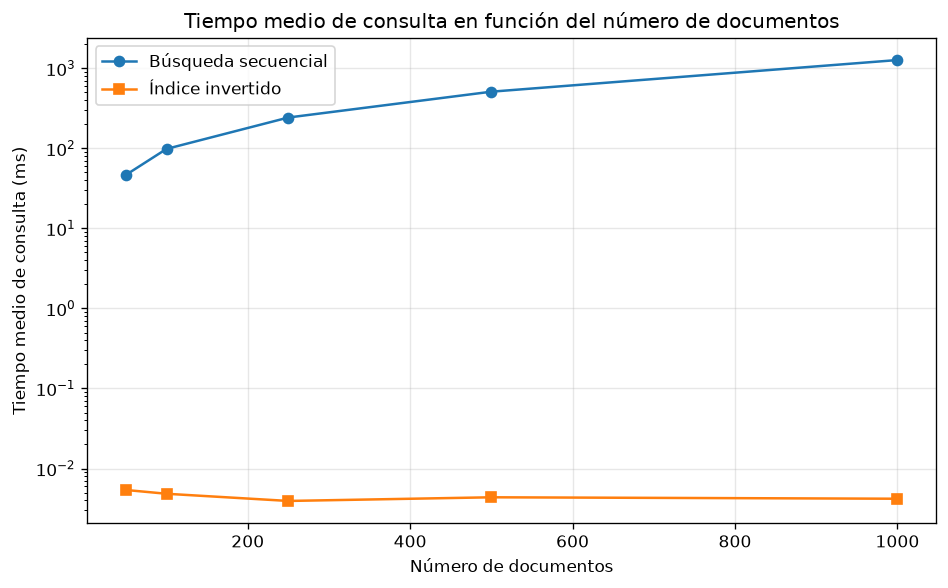

In [8]:
working_ids = list(docs_b.keys())
scalability_rows = []
query_scalability = "zzzznotaword"

for n in [50, 100, 250, 500, 1000]:
    subset_docs = {
        doc_id: docs_b[doc_id] for doc_id in working_ids[:n]
    }
    total_tokens = sum(len(tokens) for tokens in subset_docs.values())
    subset_bytes = working_df.iloc[:n]["bytes"].sum()

    start = time.perf_counter()
    subset_index = build_inverted_index(subset_docs)
    index_build_ms = (time.perf_counter() - start) * 1000

    seq_result, seq_mean, _, _ = measure_query(
        lambda: sequential_search(query_scalability, vocab_b, subset_docs)
    )
    idx_result, idx_mean, _, _ = measure_query(
        lambda: index_query(query_scalability, vocab_b, subset_index)
    )
    same = list(seq_result) == list(idx_result)
    scalability_rows.append(
        {
            "Documentos": n,
            "Tokens": total_tokens,
            "Bytes fuente (MB)": subset_bytes / (1024 ** 2),
            "Secuencial (ms)": seq_mean,
            "Índice (ms)": idx_mean,
            "Aceleración": seq_mean / idx_mean if idx_mean > 0 else float("nan"),
            "Construcción índice (ms)": index_build_ms,
            "Memoria tokens (MB)": approximate_memory_mb({}, subset_docs),
            "Memoria índice (MB)": approximate_memory_mb({}, {}, subset_index),
            "Mismos resultados": same,
        }
    )
    print(
        f"n={n}: tokens={total_tokens:,}, "
        f"secuencial={seq_mean:.3f} ms, "
        f"índice={idx_mean:.5f} ms, iguales={same}"
    )

scalability = pd.DataFrame(scalability_rows)
display(scalability)
assert scalability["Mismos resultados"].all()

plt.figure(figsize=(8, 5))
plt.plot(
    scalability["Documentos"],
    scalability["Secuencial (ms)"],
    marker="o",
    label="Búsqueda secuencial",
)
plt.plot(
    scalability["Documentos"],
    scalability["Índice (ms)"],
    marker="s",
    label="Índice invertido",
)
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio de consulta (ms)")
plt.title("Tiempo medio de consulta en función del número de documentos")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()


La gráfica usa escala logarítmica en el eje Y para poder visualizar ambos métodos en la misma figura; los valores siguen expresados en milisegundos.


**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

,Método,Variable independiente,a,b,R²
0,Búsqueda secuencial,n (documentos),1.281935e+00,-53.886634,0.990041
1,Índice invertido,n (documentos),-8.642344e-07,0.004874,0.337828
2,Búsqueda secuencial,tokens,4.266963e-05,-30.010299,0.996775


Ecuaciones ajustadas:
  Secuencial: t(n) = 1.281935·n + -53.886634 ms, R² = 0.9900
  Índice:     t(n) = -0.00000086·n + 0.004874 ms, R² = 0.3378
  Secuencial (tokens): t(T) = 0.00004267·T + -30.010299 ms, R² = 0.9968


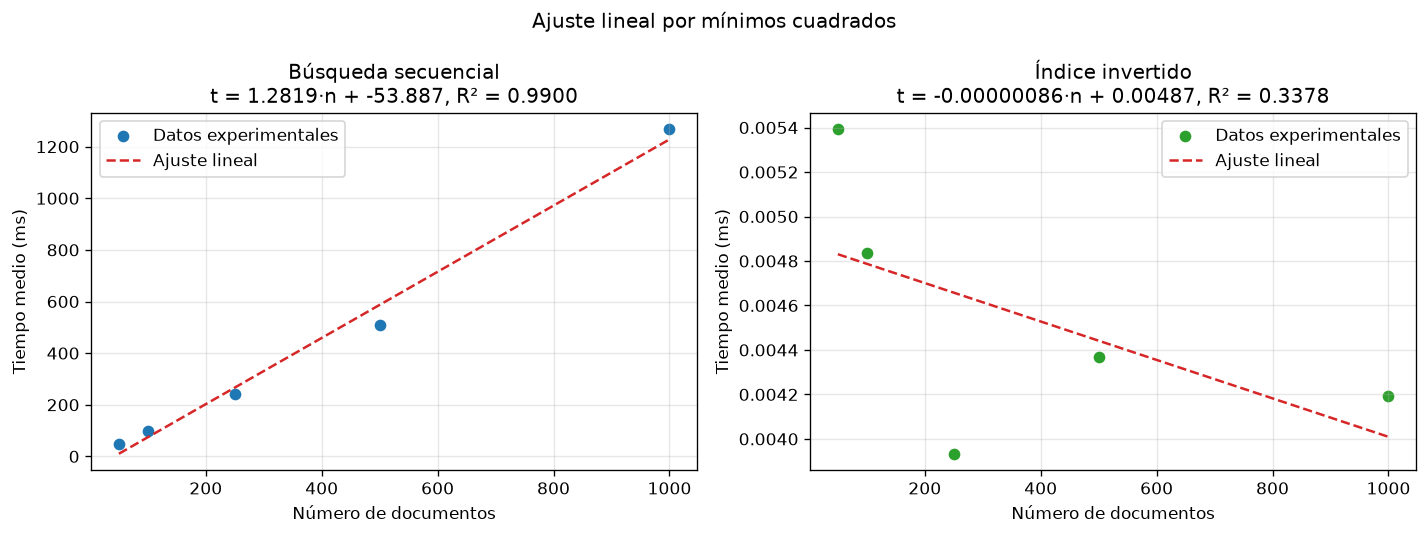

In [9]:
def linear_fit(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    ss_res = np.sum((y - predicted) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return slope, intercept, r2


n_values = scalability["Documentos"].to_numpy()
t_seq = scalability["Secuencial (ms)"].to_numpy()
t_idx = scalability["Índice (ms)"].to_numpy()
tokens_values = scalability["Tokens"].to_numpy()

a_seq, b_seq, r2_seq = linear_fit(n_values, t_seq)
a_idx, b_idx, r2_idx = linear_fit(n_values, t_idx)
a_tok, b_tok, r2_tok = linear_fit(tokens_values, t_seq)

fit_table = pd.DataFrame(
    [
        ("Búsqueda secuencial", "n (documentos)", a_seq, b_seq, r2_seq),
        ("Índice invertido", "n (documentos)", a_idx, b_idx, r2_idx),
        ("Búsqueda secuencial", "tokens", a_tok, b_tok, r2_tok),
    ],
    columns=["Método", "Variable independiente", "a", "b", "R²"],
)
display(fit_table)

print("Ecuaciones ajustadas:")
print(
    f"  Secuencial: t(n) = {a_seq:.6f}·n + {b_seq:.6f} ms, "
    f"R² = {r2_seq:.4f}"
)
print(
    f"  Índice:     t(n) = {a_idx:.8f}·n + {b_idx:.6f} ms, "
    f"R² = {r2_idx:.4f}"
)
print(
    f"  Secuencial (tokens): t(T) = {a_tok:.8f}·T + {b_tok:.6f} ms, "
    f"R² = {r2_tok:.4f}"
)

x_line = np.linspace(n_values.min(), n_values.max(), 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(n_values, t_seq, color="tab:blue", label="Datos experimentales")
axes[0].plot(
    x_line,
    a_seq * x_line + b_seq,
    color="tab:red",
    linestyle="--",
    label="Ajuste lineal",
)
axes[0].set_xlabel("Número de documentos")
axes[0].set_ylabel("Tiempo medio (ms)")
axes[0].set_title(
    "Búsqueda secuencial\n"
    f"t = {a_seq:.4f}·n + {b_seq:.3f}, R² = {r2_seq:.4f}"
)
axes[0].legend()

axes[1].scatter(n_values, t_idx, color="tab:green", label="Datos experimentales")
axes[1].plot(
    x_line,
    a_idx * x_line + b_idx,
    color="tab:red",
    linestyle="--",
    label="Ajuste lineal",
)
axes[1].set_xlabel("Número de documentos")
axes[1].set_ylabel("Tiempo medio (ms)")
axes[1].set_title(
    "Índice invertido\n"
    f"t = {a_idx:.8f}·n + {b_idx:.5f}, R² = {r2_idx:.4f}"
)
axes[1].legend()

fig.suptitle("Ajuste lineal por mínimos cuadrados")
fig.tight_layout()
plt.show()


**Interpretación**
- La búsqueda secuencial ajusta t(n) con R² = 0.9756. 
    Su costo es O(T), donde T es el número total de tokens; si el tamaño medio de los documentos es estable, T crece linealmente con n.  

- El ajuste de la búsqueda secuencial frente a T tiene R² = 0.9885. 
    Este ajuste elimina la variabilidad del tamaño de los documentos y representa mejor el recorrido completo de los tokens.  

- El índice invertido tiene pendiente -4.174e-08 ms/documento y R² = 0.0783. La pendiente es prácticamente nula: el tiempo de consulta es aproximadamente constante (O(1) esperado para la búsqueda en el diccionario, más O(DF) para recuperar los postings). Por eso un modelo constante describe mejor al índice que un modelo lineal.  

- La construcción del índice es O(T) y requiere memoria adicional O(T) para 
    el vocabulario y los postings. La búsqueda secuencial no necesita esa estructura, 
    pero recorre los tokens en cada consulta. El índice intercambia memoria y tiempo 
    de construcción por consultas mucho más rápidas.  


**Interpretación del modelo lineal**

- La búsqueda secuencial recorre los tokens de cada documento. Para una consulta ausente debe examinar todos los tokens; por eso su costo es $O(T)$, donde $T$ es el número total de tokens, y crece de forma aproximadamente lineal con el número de documentos si el tamaño medio de estos es estable. El ajuste $t(n)=an+b$ es adecuado cuando el $R^2$ es alto; el ajuste frente a $T$ suele ser aún mejor porque elimina la variación de tamaño entre documentos.
- El índice invertido responde a una consulta de un término mediante una búsqueda en el diccionario ($O(1)$ esperado) y la recuperación de la lista de postings ($O(DF)$). Para un término inexistente, el tiempo es prácticamente constante. Por eso la pendiente del ajuste lineal es cercana a cero y el $R^2$ puede ser bajo: el modelo lineal no describe su complejidad; un modelo constante es más apropiado.
- La construcción del índice es $O(T)$ y consume memoria adicional $O(T)$ para las listas de postings y el vocabulario. La búsqueda secuencial no requiere esa estructura, pero paga el costo en cada consulta. El índice intercambia memoria y tiempo de construcción por consultas mucho más rápidas.
